In [9]:
# =============================================================================
# CELDA 1: SETUP, IMPORTACIONES Y RUTAS GLOBALES - CORREGIDA
# =============================================================================
import pandas as pd
import numpy as np
import os
import glob
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import fft
from scipy.stats import wilcoxon
import warnings
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
import joblib
from tqdm.notebook import tqdm

warnings.filterwarnings('ignore')

# --- Estilo de Gráficos ---
sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams.update({
    'figure.figsize': (15, 7), 'axes.titlesize': 18, 'axes.labelsize': 14,
    'xtick.labelsize': 12, 'ytick.labelsize': 12, 'legend.fontsize': 12
})

# --- Rutas (ajusta estas rutas a la estructura de tu proyecto) ---
PROJECT_ROOT_DIR = os.getcwd()
ORIGINAL_DATA_FILE = os.path.join(PROJECT_ROOT_DIR, 'CSVs', 'Air_Quality.csv')
SIMULATED_DATA_ROOT_DIR = os.path.join(PROJECT_ROOT_DIR, 'CSVs', 'simulados')
IMPUTATIONS_BASE_DIR = os.path.join(PROJECT_ROOT_DIR, 'imputaciones')
PREDICTIONS_BASE_DIR = os.path.join(PROJECT_ROOT_DIR, 'predicciones')

# Directorio para guardar los nuevos resultados y gráficos de este notebook
ANALYSIS_OUTPUT_DIR = os.path.join(PROJECT_ROOT_DIR, 'analisis_avanzado')
os.makedirs(ANALYSIS_OUTPUT_DIR, exist_ok=True)

# --- Parámetros clave del estudio ---
TARGET_VARIABLE = 'AQI'
CITY_FOR_ANALYSIS = 'Brasilia'
SCENARIO_FOR_ANALYSIS = 'BlockRows_60h_20percent'
REP_FOR_ANALYSIS = 1

# --- *** CORRECCIÓN AQUÍ: PARÁMETROS DE PREDICCIÓN Y ANÁLISIS AÑADIDOS *** ---
EXOGENOUS_COLS = ['CO', 'NO2', 'SO2', 'O3', 'PM2.5', 'PM10']
TIME_FEATURES = ['Hour', 'DayOfWeek', 'Month']
N_LAGS_AQI = 120
N_LAGS_EXO = 120
PREDICTION_HORIZON_FOR_ANALYSIS = 60
HISTORY_LEN_FOR_PLOT = 300 # <--- ¡LA VARIABLE QUE FALTABA!
# --- *** FIN DE LA CORRECCIÓN *** ---


print("Entorno configurado y rutas definidas.")

Entorno configurado y rutas definidas.


In [10]:
# =============================================================================
# CELDA 2: CARGA DE DATOS Y FUNCIONES AUXILIARES
# =============================================================================

# --- Cargar el Ground Truth ---
try:
    df_ground_truth_raw = pd.read_csv(ORIGINAL_DATA_FILE)
    if 'CO2' in df_ground_truth_raw.columns:
        df_ground_truth_raw = df_ground_truth_raw.drop(columns=['CO2'])
    df_ground_truth_raw[TARGET_VARIABLE] = df_ground_truth_raw[TARGET_VARIABLE].ffill().bfill()
    print("DataFrame Ground Truth cargado.")
except FileNotFoundError:
    print(f"ERROR: No se encontró el archivo original en {ORIGINAL_DATA_FILE}")
    # Salir o manejar el error
    
# --- Funciones para localizar archivos ---
def find_imputed_file(imputation_method_folder, city, scenario, rep=1):
    """Encuentra la ruta a un archivo CSV imputado específico."""
    city_safe = city.replace(" ", "_")
    base_path = os.path.join(IMPUTATIONS_BASE_DIR, imputation_method_folder, 'CSVs', city_safe, scenario)
    files = glob.glob(os.path.join(base_path, f"*_rep{rep}_*.csv"))
    if files:
        return files[0]
    return None

def find_nan_file(city, scenario, rep=1):
    """Encuentra el archivo con NaNs simulados."""
    city_safe = city.replace(" ", "_")
    base_path = os.path.join(SIMULATED_DATA_ROOT_DIR, city_safe, scenario)
    files = glob.glob(os.path.join(base_path, f"*_rep{rep}_*_with_nans.csv"))
    if files:
        return files[0]
    return None

# Seleccionamos los datos de la ciudad de análisis
df_gt_city = df_ground_truth_raw[df_ground_truth_raw['City'] == CITY_FOR_ANALYSIS].reset_index(drop=True)

print(f"Funciones auxiliares definidas. Datos para '{CITY_FOR_ANALYSIS}' preparados.")

DataFrame Ground Truth cargado.
Funciones auxiliares definidas. Datos para 'Brasilia' preparados.


--- Iniciando Análisis de Frecuencia (FFT) ---
Analizando el segmento de índice 756 a 1016
Gráfico de FFT guardado en: c:\Users\fdemiguel\Documentos\TFM_Ambiental\AIR QUALITY\analisis_avanzado\fft_analysis.png


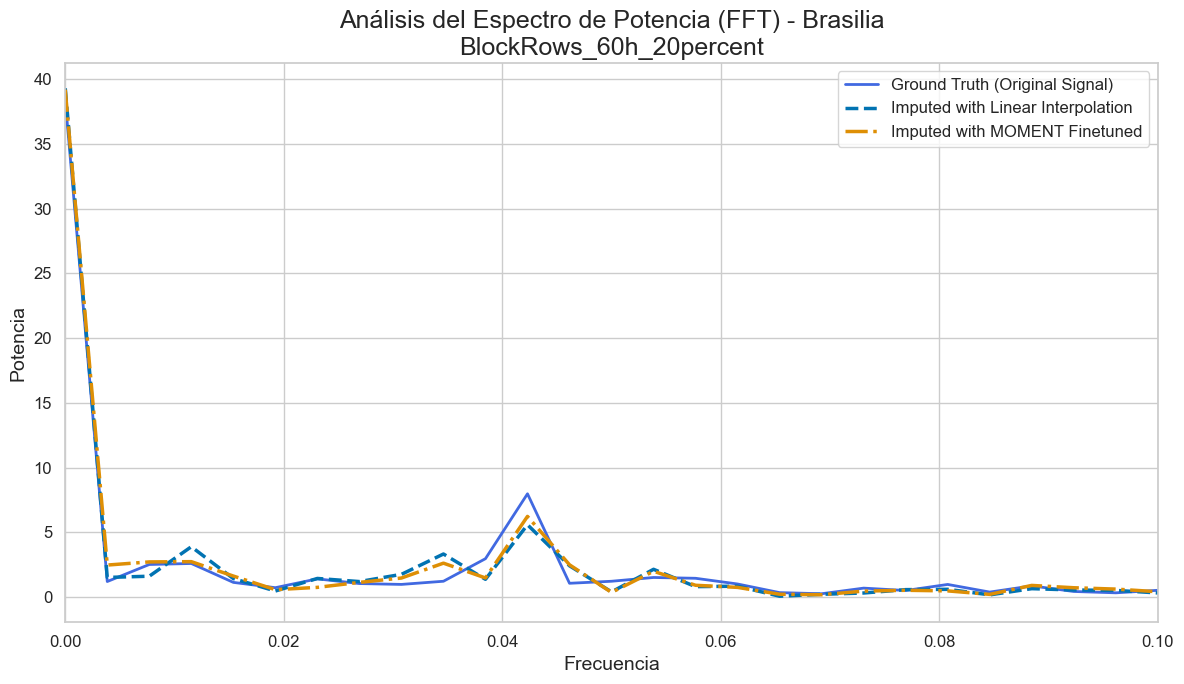

In [11]:
# =============================================================================
# CELDA 3: ANÁLISIS DE FRECUENCIA (FFT) PARA LA PARADOJA DEL PREPROCESADOR
# =============================================================================
print("--- Iniciando Análisis de Frecuencia (FFT) ---")

# --- Mapeo de nombres de carpeta a nombres legibles ---
# Ajusta los nombres de las carpetas si son diferentes
imputation_map = {
    'Linear Interpolation': 'Linear Interpolation',
    'MOMENT_FT_Optimized': 'MOMENT Finetuned'
}

# --- Cargar los datos necesarios ---
# 1. Ground Truth
series_gt = df_gt_city[TARGET_VARIABLE]

# 2. Archivo con NaNs para saber dónde estaba el hueco
nan_file_path = find_nan_file(CITY_FOR_ANALYSIS, SCENARIO_FOR_ANALYSIS, REP_FOR_ANALYSIS)
if nan_file_path:
    df_with_nans = pd.read_csv(nan_file_path)
    nan_mask = df_with_nans[TARGET_VARIABLE].isnull()
    # Encontrar el bloque de nulos más grande para visualizar
    nan_blocks = nan_mask.astype(int).diff().fillna(0)
    starts = nan_blocks[nan_blocks == 1].index
    ends = nan_blocks[nan_blocks == -1].index
    if not ends.empty and starts[0] > ends[0]:
        starts = starts.insert(0,0) # If it starts with NaNs
    if len(starts) > len(ends):
        ends = ends.append(pd.Index([len(nan_mask)]))

    block_lengths = ends.values - starts.values
    longest_block_idx = np.argmax(block_lengths)
    start_idx = starts[longest_block_idx] - 100 # Un poco de contexto antes
    end_idx = ends[longest_block_idx] + 100   # Un poco de contexto después
    start_idx = max(0, start_idx)
    end_idx = min(len(series_gt), end_idx)
    print(f"Analizando el segmento de índice {start_idx} a {end_idx}")
else:
    print("No se encontró el archivo con NaNs. Usando un segmento de ejemplo.")
    start_idx, end_idx = 1000, 1500

# --- Función para calcular el espectro de potencia ---
def get_power_spectrum(series):
    N = len(series)
    yf = fft.fft(series.values)
    xf = fft.fftfreq(N, 1)[:N//2] # Frecuencia (asumiendo 1 unidad de tiempo por muestra)
    power = 2.0/N * np.abs(yf[0:N//2])
    return xf, power

# --- Generar y plotear los espectros ---
plt.figure(figsize=(12, 7))
ax = plt.gca()

# 1. Espectro del Ground Truth
xf_gt, power_gt = get_power_spectrum(series_gt[start_idx:end_idx])
ax.plot(xf_gt, power_gt, label='Ground Truth (Original Signal)', color='royalblue', linewidth=2)

# 2. Espectro de los datos imputados
for folder_name, plot_label in imputation_map.items():
    file_path = find_imputed_file(folder_name, CITY_FOR_ANALYSIS, SCENARIO_FOR_ANALYSIS, REP_FOR_ANALYSIS)
    if file_path:
        df_imputed = pd.read_csv(file_path)
        series_imputed = df_imputed[TARGET_VARIABLE]
        xf_imputed, power_imputed = get_power_spectrum(series_imputed[start_idx:end_idx])
        linestyle = '--' if 'Linear' in plot_label else '-.'
        ax.plot(xf_imputed, power_imputed, label=f'Imputed with {plot_label}', linestyle=linestyle, linewidth=2.5)

ax.set_title(f'Análisis del Espectro de Potencia (FFT) - {CITY_FOR_ANALYSIS}\n{SCENARIO_FOR_ANALYSIS}')
ax.set_xlabel('Frecuencia')
ax.set_ylabel('Potencia')
ax.set_xlim(0, 0.1) # Enfocarse en las frecuencias más bajas e interesantes
ax.legend()
ax.grid(True)
plt.tight_layout()

# Guardar la figura
fft_plot_path = os.path.join(ANALYSIS_OUTPUT_DIR, 'fft_analysis.png')
plt.savefig(fft_plot_path, dpi=300)
print(f"Gráfico de FFT guardado en: {fft_plot_path}")
plt.show()

--- Iniciando Análisis de Importancia de Características ---
Entrenando RF Forecaster con datos de 'Linear Interpolation'...
Entrenando RF Forecaster con datos de 'MOMENT Finetuned'...
Gráfico de importancia de características guardado en: c:\Users\fdemiguel\Documentos\TFM_Ambiental\AIR QUALITY\analisis_avanzado\feature_importance.png


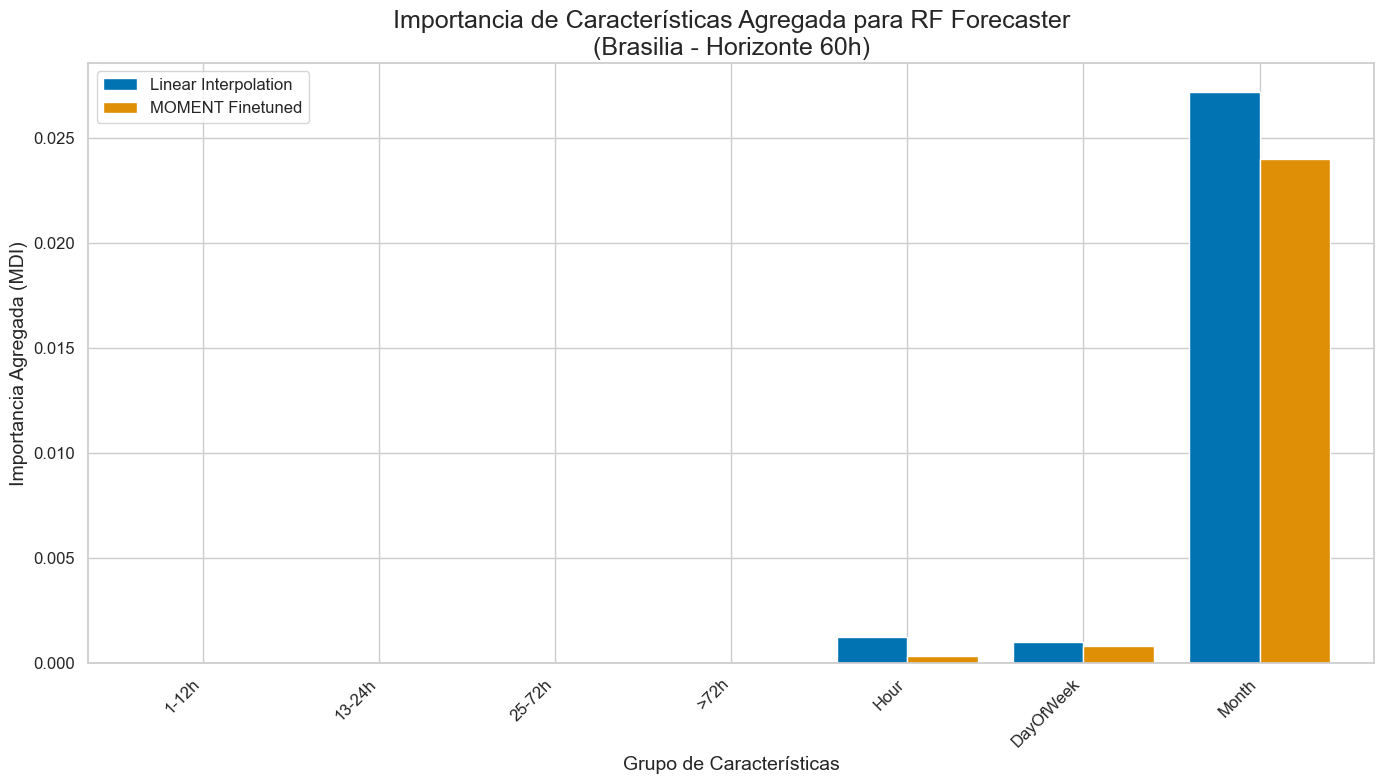

In [12]:
# =============================================================================
# CELDA 4: ANÁLISIS DE IMPORTANCIA DE CARACTERÍSTICAS (FEATURE IMPORTANCE)
# =============================================================================
print("--- Iniciando Análisis de Importancia de Características ---")

# --- Recrear la función de generación de features de tu notebook de predicción ---
def create_multivariate_lagged_features_rf(df, target_col, exo_cols, time_cols, n_lags_target, n_lags_exo, horizon):
    features = []
    # Usamos los mismos lags que en tu script original
    lags_target = list(range(horizon, n_lags_target + horizon))
    lags_exo = list(range(horizon, n_lags_exo + horizon))
    
    for i in lags_target:
        features.append(df[target_col].shift(i).rename(f'{target_col}_lag{i}'))
    for exo_col in exo_cols:
        if exo_col != target_col:
            for i in lags_exo:
                features.append(df[exo_col].shift(i).rename(f'{exo_col}_lag{i}'))
    for tf_col in time_cols:
        if tf_col in df.columns:
            features.append(df[tf_col])
    return pd.concat(features, axis=1)

# --- Parámetros del RF Forecaster (de tu notebook de predicción) ---
N_LAGS_AQI = 120
N_LAGS_EXO = 120
PREDICTION_HORIZON_FOR_ANALYSIS = 60 # Analizamos para el horizonte más lejano
EXOGENOUS_COLS = ['CO', 'NO2', 'SO2', 'O3', 'PM2.5', 'PM10']
TIME_FEATURES = ['Hour', 'DayOfWeek', 'Month']

# --- Mapeo de nombres de carpeta a nombres legibles (ajusta si es necesario) ---
imputation_map = {
    'Linear Interpolation': 'Linear Interpolation',
    'MOMENT_FT_Optimized': 'MOMENT Finetuned'
}

# --- Entrenar modelos y obtener importancias ---
importances = {}
for folder_name, plot_label in imputation_map.items():
    print(f"Entrenando RF Forecaster con datos de '{plot_label}'...")
    file_path = find_imputed_file(folder_name, CITY_FOR_ANALYSIS, SCENARIO_FOR_ANALYSIS, REP_FOR_ANALYSIS)
    if not file_path:
        print(f"  Archivo no encontrado para {plot_label}, saltando.")
        continue
        
    df_imputed = pd.read_csv(file_path)
    # Asegurarse de que las columnas de tiempo existen
    df_imputed['Date'] = pd.to_datetime(df_imputed['Date'])
    df_imputed['Hour'] = df_imputed['Date'].dt.hour
    df_imputed['DayOfWeek'] = df_imputed['Date'].dt.dayofweek
    df_imputed['Month'] = df_imputed['Date'].dt.month
    
    X = create_multivariate_lagged_features_rf(df_imputed, TARGET_VARIABLE, EXOGENOUS_COLS, TIME_FEATURES, N_LAGS_AQI, N_LAGS_EXO, PREDICTION_HORIZON_FOR_ANALYSIS)
    y = df_gt_city[TARGET_VARIABLE]

    full_data = pd.concat([X, y], axis=1).dropna()
    X_train, y_train = full_data.drop(columns=[TARGET_VARIABLE]), full_data[TARGET_VARIABLE]

    # Usamos un modelo un poco más rápido para este análisis interactivo
    model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
    model.fit(X_train, y_train)
    
    importances[plot_label] = pd.Series(model.feature_importances_, index=X_train.columns)

# --- Visualizar las importancias ---
if importances:
    df_importances = pd.DataFrame(importances)
    
    # Agrupar lags para mejor visualización
    lag_cols = [c for c in df_importances.index if 'lag' in c]
    time_cols = [c for c in df_importances.index if c in TIME_FEATURES]
    
    df_lag_imp = df_importances.loc[lag_cols]
    df_time_imp = df_importances.loc[time_cols]
    
    # --- *** CORRECCIÓN APLICADA AQUÍ *** ---
    # Extraer el número del lag como una serie numérica
    lag_numbers = df_lag_imp.index.str.extract(r'_lag(\d+)').astype(int).iloc[:, 0]
    
    # Usar pd.cut para crear los grupos de forma vectorizada
    bins = [0, 12, 24, 72, np.inf]
    labels = ['1-12h', '13-24h', '25-72h', '>72h']
    df_lag_imp['lag_group'] = pd.cut(lag_numbers, bins=bins, labels=labels, right=True)
    # --- *** FIN DE LA CORRECCIÓN *** ---

    df_lag_summary = df_lag_imp.groupby('lag_group').sum()
    
    df_summary = pd.concat([df_lag_summary, df_time_imp])
    
    df_summary.plot(kind='bar', figsize=(14, 8), width=0.8)
    plt.title(f'Importancia de Características Agregada para RF Forecaster\n({CITY_FOR_ANALYSIS} - Horizonte {PREDICTION_HORIZON_FOR_ANALYSIS}h)')
    plt.ylabel('Importancia Agregada (MDI)')
    plt.xlabel('Grupo de Características')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    
    fi_plot_path = os.path.join(ANALYSIS_OUTPUT_DIR, 'feature_importance.png')
    plt.savefig(fi_plot_path, dpi=300)
    print(f"Gráfico de importancia de características guardado en: {fi_plot_path}")
    plt.show()
else:
    print("No se pudieron generar los datos de importancia de características.")

In [13]:
# =============================================================================
# CELDA 5: TEST DE SIGNIFICANCIA ESTADÍSTICA (WILCOXON) - CORREGIDA
# =============================================================================
print("--- Iniciando Tests de Significancia ---")

# --- Cargar los resultados de predicción de TODOS los modelos ---
# Usaremos los resultados del RandomForest Forecaster como ejemplo
prediction_method_folder = 'RandomForest_full_FT' 
metrics_file = os.path.join(PREDICTIONS_BASE_DIR, prediction_method_folder, 'metricas', f'ALL_prediction_metrics_detailed_{prediction_method_folder}.csv')

try:
    df_preds = pd.read_csv(metrics_file)
    print(f"Métricas de predicción cargadas desde {metrics_file}")
except FileNotFoundError:
    print(f"ERROR: No se encontró el archivo de métricas {metrics_file}. No se pueden ejecutar los tests.")
    df_preds = pd.DataFrame()

if not df_preds.empty:
    # --- *** CORRECCIÓN APLICADA AQUÍ *** ---
    # La clave es agrupar por las condiciones experimentales (Ciudad, Escenario, Horizonte)
    # y usar el MAE de cada método de imputación como columnas.
    # Usamos aggfunc='mean' por si en el futuro incluyes más repeticiones. 
    # Con tus datos actuales, como solo hay una repetición, simplemente tomará ese valor.
    df_pivot = df_preds.pivot_table(
        index=['City', 'Scenario', 'Horizon_h'], # Usamos estas como las "pruebas" pareadas
        columns='Imputation_Method',
        values='MAE',
        aggfunc='mean' # Agregamos por si hay múltiples repeticiones (aunque ahora solo hay una)
    ).dropna()
    
    # Renombrar métodos para que quepan mejor en las tablas
    rename_map = {
        'Linear Interpolation': 'Linear',
        'LSTM-VAE': 'LSTM-VAE',
        'MOMENT Finetuned': 'MOMENT-FT',
        'MOMENT Pretrained': 'MOMENT-Pre',
        'Random Forest': 'RF Imputer',
        'SARIMA': 'SARIMA'
    }
    df_pivot = df_pivot.rename(columns=rename_map)
    
    print("\nVista de la tabla pivotada para el test:")
    print(df_pivot.head())

    imputation_methods = df_pivot.columns
    
    # --- Comparar 'Linear' contra los demás ---
    base_method = 'Linear'
    if base_method not in imputation_methods:
        print(f"ERROR: El método base '{base_method}' no está en los resultados.")
    else:
        results = []
        for method_to_compare in imputation_methods:
            if method_to_compare == base_method:
                continue
            
            # Wilcoxon signed-rank test
            # H0: la mediana de las diferencias entre pares es cero (no hay diferencia)
            # H1: la mediana de las diferencias no es cero (hay diferencia)
            try:
                stat, p_value = wilcoxon(df_pivot[base_method], df_pivot[method_to_compare])
                
                # Interpretación
                if p_value < 0.05:
                    significance = 'Yes'
                    # Comprobar qué método es mejor
                    if df_pivot[base_method].mean() < df_pivot[method_to_compare].mean():
                        conclusion = f"'{base_method}' es significativamente mejor."
                    else:
                        conclusion = f"'{method_to_compare}' es significativamente mejor."
                else:
                    significance = 'No'
                    conclusion = "No hay diferencia significativa."

                results.append({
                    'Comparison': f'{base_method} vs {method_to_compare}',
                    'Statistic': stat,
                    'p_value': f"{p_value:.4f}",
                    'Significant (p < 0.05)': significance,
                    'Conclusion': conclusion
                })
            except ValueError as e:
                # Esto puede pasar si las dos series son idénticas
                results.append({
                    'Comparison': f'{base_method} vs {method_to_compare}',
                    'Statistic': 'N/A',
                    'p_value': 'N/A',
                    'Significant (p < 0.05)': 'N/A',
                    'Conclusion': f"Error en el test: {e}"
                })
            
        df_wilcoxon = pd.DataFrame(results)
        print("\nResultados del Test de Wilcoxon (Comparando MAE de pipelines con RF Forecaster):")
        print(df_wilcoxon.to_string())
        
        # Guardar resultados
        wilcoxon_path = os.path.join(ANALYSIS_OUTPUT_DIR, 'wilcoxon_test_results.csv')
        df_wilcoxon.to_csv(wilcoxon_path, index=False)
        print(f"\nResultados del test guardados en: {wilcoxon_path}")

--- Iniciando Tests de Significancia ---
Métricas de predicción cargadas desde c:\Users\fdemiguel\Documentos\TFM_Ambiental\AIR QUALITY\predicciones\RandomForest_full_FT\metricas\ALL_prediction_metrics_detailed_RandomForest_full_FT.csv

Vista de la tabla pivotada para el test:
Imputation_Method                           LSTM-VAE    Linear  MOMENT-FT  \
City     Scenario                Horizon_h                                  
Brasilia BlockRows_12h_20percent 12         1.151025  1.061690   1.099441   
                                 24         1.288743  1.186419   1.229607   
                                 36         1.392084  1.269906   1.335695   
                                 48         1.451707  1.332327   1.389808   
                                 60         1.499350  1.367201   1.446026   

Imputation_Method                           MOMENT-Pre  RF Imputer    SARIMA  
City     Scenario                Horizon_h                                    
Brasilia BlockRows_12h_20

In [14]:
# =============================================================================
# CELDA 6: PROPAGACIÓN DE INCERTIDUMBRE (MONTE CARLO) - CORREGIDA
# =============================================================================
print("--- Definiendo funciones para la Propagación de Incertidumbre ---")
# --- PARÁMETROS PARA UQ ---
N_MONTE_CARLO_SAMPLES = 50 # Empezar con un número bajo (e.g., 50-100) para pruebas
N_LAGS = list(range(1, 13)) + [24, 48, 72] # Lags para el imputer univariante de RF

# --- *** FUNCIÓN AÑADIDA AQUÍ *** ---
def create_univariant_features(df, target_col, time_cols, lags):
    """Crea features univariantes (lags y tiempo) para un modelo."""
    features = pd.DataFrame(index=df.index)
    for tf_col in time_cols:
        if tf_col in df.columns:
            features[tf_col] = df[tf_col]
    for lag in lags:
        features[f'{target_col}_lag{lag}'] = df[target_col].shift(lag)
    return features
# --- *** FIN DE LA ADICIÓN *** ---

# --- 1. Funciones para generar imputaciones probabilísticas ---

def generate_rf_imputation_samples(df_with_nans, trained_rf_imputer, n_samples):
    """Genera n_samples de imputaciones usando la varianza de los árboles de un RF."""
    # Añadir features de tiempo si no existen
    if not all(col in df_with_nans.columns for col in TIME_FEATURES):
        df_with_nans['Date'] = pd.to_datetime(df_with_nans['Date'])
        df_with_nans['Hour'] = df_with_nans['Date'].dt.hour
        df_with_nans['DayOfWeek'] = df_with_nans['Date'].dt.dayofweek
        df_with_nans['Month'] = df_with_nans['Date'].dt.month

    df_imputed = df_with_nans.copy().interpolate(method='linear').ffill().bfill()
    nan_indices_mask = df_with_nans[TARGET_VARIABLE].isnull()
    
    if not nan_indices_mask.any():
        return [df_with_nans.copy() for _ in range(n_samples)]
        
    # Crear features una vez
    X = create_univariant_features(df_imputed, TARGET_VARIABLE, TIME_FEATURES, N_LAGS)
    X_to_impute = X.loc[nan_indices_mask]
    
    # Asegurarse de que las features no tengan NaNs (debido a los lags al inicio de la serie)
    valid_indices = X_to_impute.dropna().index
    X_to_impute_clean = X_to_impute.loc[valid_indices]

    if X_to_impute_clean.empty:
        print("Advertencia: No hay puntos válidos para imputar con RF después de crear lags.")
        return [df_imputed.copy() for _ in range(n_samples)] # Devolver la versión interpolada
        
    # Obtener predicciones de cada árbol
    tree_predictions = np.array([tree.predict(X_to_impute_clean) for tree in trained_rf_imputer.estimators_])
    
    # Generar Muestras
    imputed_datasets = []
    for _ in tqdm(range(n_samples), desc="Generando muestras de imputación RF", leave=False):
        # Para cada valor faltante, muestrear de las predicciones de los árboles
        sample_indices = np.random.randint(0, len(trained_rf_imputer.estimators_), size=len(valid_indices))
        imputed_values = tree_predictions[sample_indices, np.arange(len(valid_indices))]
        
        df_sample = df_with_nans.copy()
        df_sample.loc[valid_indices, TARGET_VARIABLE] = imputed_values
        # Rellenar cualquier hueco restante (e.g., al principio de la serie) con interpolación
        df_sample[TARGET_VARIABLE] = df_sample[TARGET_VARIABLE].interpolate(method='linear', limit_direction='both').ffill().bfill()
        imputed_datasets.append(df_sample)
        
    return imputed_datasets


# --- 2. Función para propagar la incertidumbre ---

def propagate_uncertainty_to_forecasts(imputed_datasets, forecaster_model, horizon):
    """Toma una lista de datasets imputados y genera un forecast para cada uno."""
    all_forecasts = []
    
    for df_imputed in tqdm(imputed_datasets, desc="Propagando incertidumbre", leave=False):
        # Crear features para este dataset
        X_full = create_multivariate_lagged_features_rf(df_imputed, TARGET_VARIABLE, EXOGENOUS_COLS, TIME_FEATURES, N_LAGS_AQI, N_LAGS_EXO, horizon)
        
        # Predecir en los puntos donde tenemos features válidas
        predictable_indices = X_full.dropna().index
        if len(predictable_indices) == 0: continue
            
        X_predict = X_full.loc[predictable_indices]
        predictions = forecaster_model.predict(X_predict)
        
        # Guardar las predicciones como una serie para alinearlas con el índice de tiempo
        all_forecasts.append(pd.Series(predictions, index=predictable_indices))
        
    if not all_forecasts:
        return pd.DataFrame() # Devolver un DataFrame vacío si no se generó ningún forecast
        
    return pd.concat(all_forecasts, axis=1)

print("Funciones para UQ definidas.")

--- Definiendo funciones para la Propagación de Incertidumbre ---
Funciones para UQ definidas.


--- Ejecutando el pipeline completo de UQ ---
Entrenando RF Imputer para Brasilia...
Entrenando RF Forecaster para Brasilia...


Generando muestras de imputación RF:   0%|          | 0/50 [00:00<?, ?it/s]

Propagando incertidumbre:   0%|          | 0/50 [00:00<?, ?it/s]

Gráfico de predicción probabilística guardado en: c:\Users\fdemiguel\Documentos\TFM_Ambiental\AIR QUALITY\analisis_avanzado\probabilistic_forecast_example.png


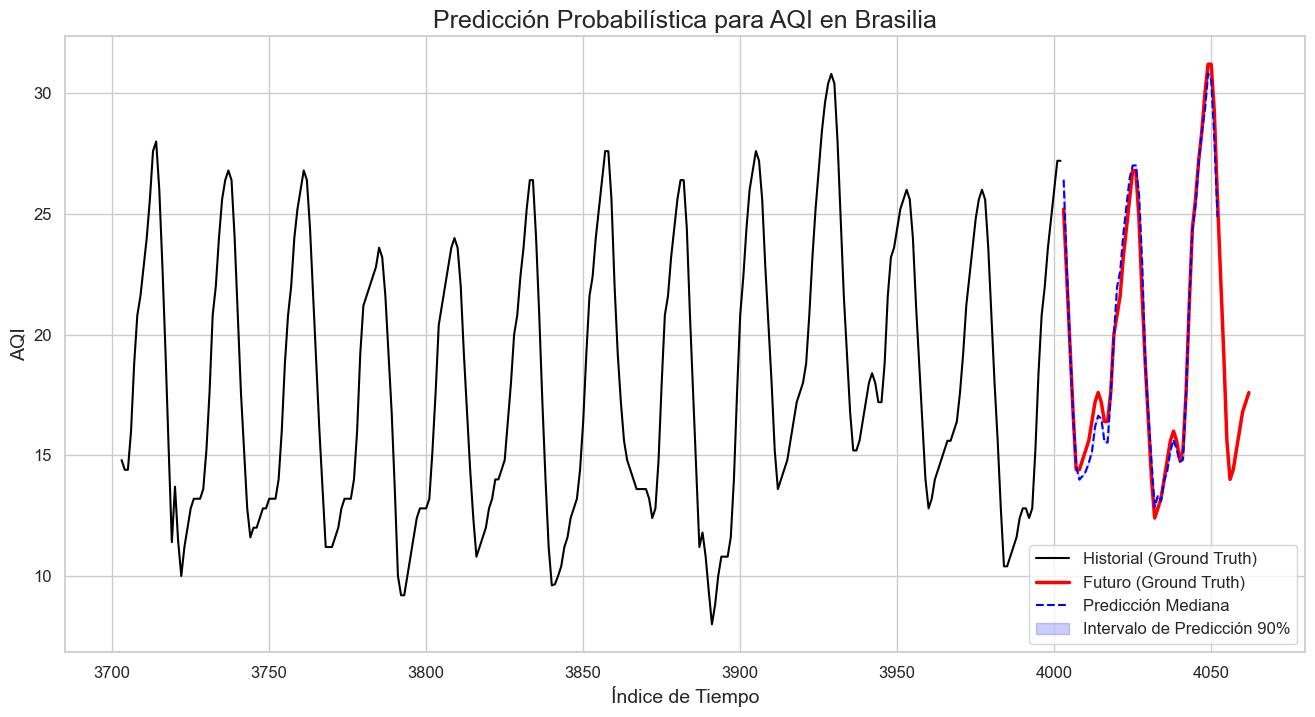

In [15]:
# =============================================================================
# CELDA 7: EJECUCIÓN DEL ANÁLISIS DE INCERTIDUMBRE Y VISUALIZACIÓN - CORREGIDA
# =============================================================================
print("--- Ejecutando el pipeline completo de UQ ---")

# --- 1. Cargar el imputer y forecaster necesarios ---
# Para este ejemplo, vamos a entrenar un RF imputer y un RF forecaster sobre la marcha
# En un escenario real, cargarías los modelos ya entrenados para consistencia.

# Asegurarse de que df_gt_city tiene columnas de tiempo
df_gt_city['Date'] = pd.to_datetime(df_gt_city['Date'])
df_gt_city['Hour'] = df_gt_city['Date'].dt.hour
df_gt_city['DayOfWeek'] = df_gt_city['Date'].dt.dayofweek
df_gt_city['Month'] = df_gt_city['Date'].dt.month

# Entrenar RF Imputer en datos limpios
print(f"Entrenando RF Imputer para {CITY_FOR_ANALYSIS}...")
X_imp_train_full = create_univariant_features(df_gt_city, TARGET_VARIABLE, TIME_FEATURES, N_LAGS) # Usamos N_LAGS
y_imp_train_full = df_gt_city[TARGET_VARIABLE]
train_data_imp = pd.concat([X_imp_train_full, y_imp_train_full], axis=1).dropna()
rf_imputer = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1).fit(train_data_imp.drop(columns=[TARGET_VARIABLE]), train_data_imp[TARGET_VARIABLE])

# Entrenar RF Forecaster con la imputación base (lineal)
print(f"Entrenando RF Forecaster para {CITY_FOR_ANALYSIS}...")
imputed_linear_path = find_imputed_file('Linear Interpolation', CITY_FOR_ANALYSIS, SCENARIO_FOR_ANALYSIS, REP_FOR_ANALYSIS)
df_linear = pd.read_csv(imputed_linear_path)
df_linear['Date'] = pd.to_datetime(df_linear['Date'])
df_linear['Hour'], df_linear['DayOfWeek'], df_linear['Month'] = df_linear['Date'].dt.hour, df_linear['Date'].dt.dayofweek, df_linear['Date'].dt.month
X_fore_train_full = create_multivariate_lagged_features_rf(df_linear, TARGET_VARIABLE, EXOGENOUS_COLS, TIME_FEATURES, N_LAGS_AQI, N_LAGS_EXO, PREDICTION_HORIZON_FOR_ANALYSIS)
y_fore_train_full = df_gt_city[TARGET_VARIABLE]
train_data_fore = pd.concat([X_fore_train_full, y_fore_train_full], axis=1).dropna()
rf_forecaster = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1).fit(train_data_fore.drop(columns=[TARGET_VARIABLE]), train_data_fore[TARGET_VARIABLE])

# --- 2. Generar muestras de imputación ---
df_with_nans = pd.read_csv(find_nan_file(CITY_FOR_ANALYSIS, SCENARIO_FOR_ANALYSIS, REP_FOR_ANALYSIS))
imputed_samples = generate_rf_imputation_samples(df_with_nans, rf_imputer, N_MONTE_CARLO_SAMPLES)

# --- 3. Propagar al forecast ---
probabilistic_forecasts = propagate_uncertainty_to_forecasts(imputed_samples, rf_forecaster, PREDICTION_HORIZON_FOR_ANALYSIS)

# --- 4. Visualizar un ejemplo ---
if not probabilistic_forecasts.empty:
    # Elegir un punto de inicio para la visualización
    plot_start_index = probabilistic_forecasts.index[len(probabilistic_forecasts) // 2]
    plot_end_index = plot_start_index + PREDICTION_HORIZON_FOR_ANALYSIS

    forecast_slice = probabilistic_forecasts.loc[plot_start_index:plot_end_index-1]
    if not forecast_slice.empty:
        median = forecast_slice.median(axis=1)
        p05 = forecast_slice.quantile(0.05, axis=1)
        p95 = forecast_slice.quantile(0.95, axis=1)
        
        plt.figure(figsize=(16, 8))
        
        # Historial
        history_start = plot_start_index - HISTORY_LEN_FOR_PLOT
        plt.plot(df_gt_city.loc[history_start:plot_start_index-1, TARGET_VARIABLE], label='Historial (Ground Truth)', color='black')
        
        # Ground truth del futuro
        plt.plot(df_gt_city.loc[plot_start_index:plot_end_index-1, TARGET_VARIABLE], label='Futuro (Ground Truth)', color='red', linewidth=2.5)
        
        # Predicción
        plt.plot(median, label='Predicción Mediana', color='blue', linestyle='--')
        plt.fill_between(median.index, p05, p95, color='blue', alpha=0.2, label='Intervalo de Predicción 90%')
        
        plt.title(f'Predicción Probabilística para {TARGET_VARIABLE} en {CITY_FOR_ANALYSIS}')
        plt.xlabel('Índice de Tiempo')
        plt.ylabel(TARGET_VARIABLE)
        plt.legend()
        plt.grid(True)
        
        uq_plot_path = os.path.join(ANALYSIS_OUTPUT_DIR, 'probabilistic_forecast_example.png')
        plt.savefig(uq_plot_path, dpi=300)
        print(f"Gráfico de predicción probabilística guardado en: {uq_plot_path}")
        plt.show()
else:
    print("No se generaron forecasts probabilísticos para visualizar.")

In [16]:
# =============================================================================
# CELDA 8: MÉTRICAS DE INCERTIDUMBRE (WINKLER & CRPS)
# =============================================================================

def winkler_score(y_true, lower_bound, upper_bound, alpha=0.1):
    """Calcula el Winkler Score."""
    score = np.where(
        y_true < lower_bound, (upper_bound - lower_bound) + (2 / alpha) * (lower_bound - y_true),
        np.where(
            y_true > upper_bound, (upper_bound - lower_bound) + (2 / alpha) * (y_true - upper_bound),
            (upper_bound - lower_bound)
        )
    )
    return np.mean(score)

def crps(y_true, samples):
    """Calcula el Continuous Ranked Probability Score."""
    n_samples = samples.shape[1]
    y_true_tiled = np.tile(y_true, (n_samples, 1)).T
    
    term1 = np.mean(np.abs(samples - y_true_tiled), axis=1)
    
    sum_abs_diff = 0
    for i in range(n_samples):
        for j in range(n_samples):
            sum_abs_diff += np.abs(samples[:, i] - samples[:, j])
    
    term2 = sum_abs_diff / (2 * n_samples**2)
    
    return np.mean(term1 - term2)


# --- Calcular métricas para el forecast generado ---
if 'forecast_slice' in locals() and not forecast_slice.empty:
    y_true_eval = df_gt_city.loc[forecast_slice.index, TARGET_VARIABLE].values
    samples_eval = forecast_slice.values
    
    # Asegurarse de que y_true_eval sea 1D
    if y_true_eval.ndim > 1:
        y_true_eval = y_true_eval.flatten()

    w_score = winkler_score(y_true_eval, p05.values, p95.values, alpha=0.1)
    c_score = crps(y_true_eval, samples_eval)

    print("\n--- Métricas de Evaluación Probabilística ---")
    print(f"Winkler Score (alpha=0.1): {w_score:.4f} (menor es mejor)")
    print(f"CRPS:                       {c_score:.4f} (menor es mejor)")


--- Métricas de Evaluación Probabilística ---
Winkler Score (alpha=0.1): 10.6104 (menor es mejor)
CRPS:                       0.5305 (menor es mejor)
